# **Overview**
This notebook presents my solution for Task 2 of the British Airways Data Science Virtual Internship hosted by The Forage. The objective is to develop a predictive model to identify customers likely to complete a booking, enabling proactive customer acquisition strategies. Using the customer_booking.csv dataset, I will explore, prepare, and model the data, then provide actionable business insights.

**Project Goals**

The task focuses on leveraging data and machine learning to predict booking completion. Key steps include:

* **Data Exploration:** Analyze the dataset’s structure, distributions, and potential challenges (e.g., class imbalance).

* **Data Preparation:** Handle outliers, engineer new features, and encode categorical variables.

* **Model Training:** Build a Random Forest model to predict booking_complete (0 = not completed, 1 = completed).

* **Evaluation:** Assess model performance using metrics like ROC-AUC and cross-validation.

* **Feature Importance:** Identify key predictors to inform business strategies.

* **Business Insights:** Summarize findings in a format suitable for stakeholders, including a PowerPoint slide.
**Dataset Overview**

* Source: customer_booking.csv
* Size: 50,000 rows, 14 columns
* Target Variable: booking_complete (binary: 0 or 1)
* Features: Includes numeric (e.g., purchase_lead, flight_duration) and categorical (e.g., route, sales_channel) variables.
Approach

Each step is documented with code, outputs, and explanations to demonstrate my data science process. The notebook is designed to be reproducible and showcases skills in data preprocessing, modeling, and interpretation for my portfolio.

## Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/customer_booking.csv', encoding = 'ISO-8859-1')
df.head(10)

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0
5,1,Internet,RoundTrip,3,48,20,Thu,AKLDEL,New Zealand,1,0,1,5.52,0
6,3,Internet,RoundTrip,201,33,6,Thu,AKLDEL,New Zealand,1,0,1,5.52,0
7,2,Internet,RoundTrip,238,19,14,Mon,AKLDEL,India,1,0,1,5.52,0
8,1,Internet,RoundTrip,80,22,4,Mon,AKLDEL,New Zealand,0,0,1,5.52,0
9,1,Mobile,RoundTrip,378,30,12,Sun,AKLDEL,India,0,0,0,5.52,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
num_passengers,50000.0,1.591240,1.020165,1.00,1.00,1.00,2.00,9.0
purchase_lead,50000.0,84.940480,90.451378,0.00,21.00,51.00,115.00,867.0
length_of_stay,50000.0,23.044560,33.887670,0.00,5.00,17.00,28.00,778.0
flight_hour,50000.0,9.066340,5.412660,0.00,5.00,9.00,13.00,23.0
wants_extra_baggage,50000.0,0.668780,0.470657,0.00,0.00,1.00,1.00,1.0
wants_preferred_seat,50000.0,0.296960,0.456923,0.00,0.00,0.00,1.00,1.0
wants_in_flight_meals,50000.0,0.427140,0.494668,0.00,0.00,0.00,1.00,1.0
flight_duration,50000.0,7.277561,1.496863,4.67,5.62,7.57,8.83,9.5
booking_complete,50000.0,0.149560,0.356643,0.00,0.00,0.00,0.00,1.0


In [5]:
df.describe(include = 'object').T

,count,unique,top,freq
sales_channel,50000,2,Internet,44382
trip_type,50000,3,RoundTrip,49497
flight_day,50000,7,Mon,8102
route,50000,799,AKLKUL,2680
booking_origin,50000,104,Australia,17872


In [6]:
df.duplicated().sum()

np.int64(719)

In [7]:
df = df.drop_duplicates()

Explanation:

* df.info(): Shows 50,000 rows, 14 columns, no missing values. Mix of numeric (int/float) and categorical (object) columns.
df.describe(): Key insights:

* num_passengers: Avg 1.59, mostly 1-2 people.

* purchase_lead: Avg 85 days, high SD (90 days) indicates variability; max 867 is an outlier.
* length_of_stay: Avg 23 days, high SD (34 days); max 778 is likely an outlier.
* booking_complete: Avg 0.15 (imbalanced: only 15% bookings completed).
* Missing values: None, so no imputation needed.
* Plot: Shows class imbalance (many more 0s than 1s).

Text(0.5, 1.0, 'Completed Bookings Distribution')

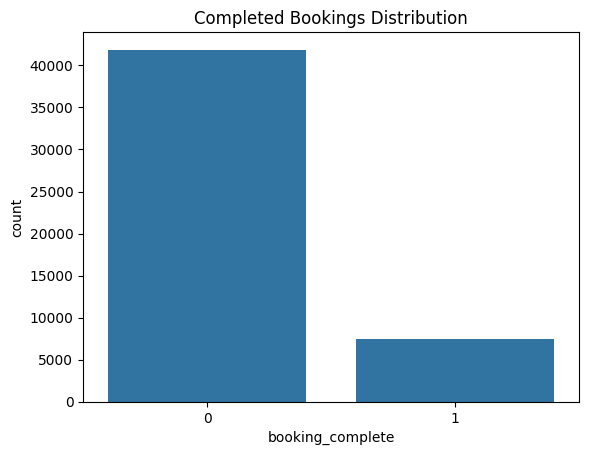

In [8]:
sns.countplot(x = 'booking_complete', data=df)
plt.title('Completed Bookings Distribution')

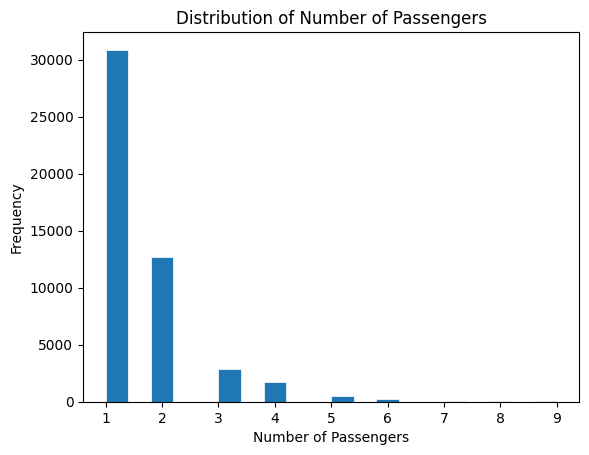

In [9]:
fig, ax = plt.subplots()

ax.hist(df['num_passengers'], bins=20, linewidth=0.5, edgecolor="white")
ax.set_title('Distribution of Number of Passengers')
ax.set_xlabel('Number of Passengers')
ax.set_ylabel('Frequency')

plt.show()

* The majorty of flights are solo travellers

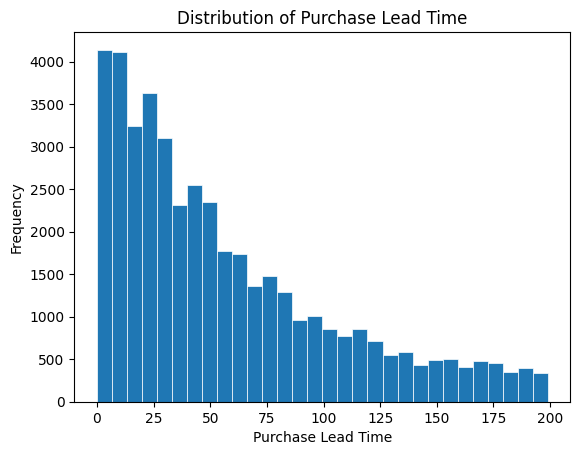

In [10]:
fig, ax = plt.subplots()
ax.hist(df[df['purchase_lead']< 200].purchase_lead ,bins= 30, linewidth=0.5, edgecolor="white")
ax.set_title('Distribution of Purchase Lead Time')
ax.set_xlabel('Purchase Lead Time')
ax.set_ylabel('Frequency')
plt.show()

* Most travellers book there flights between 0 and 25 days before travel date

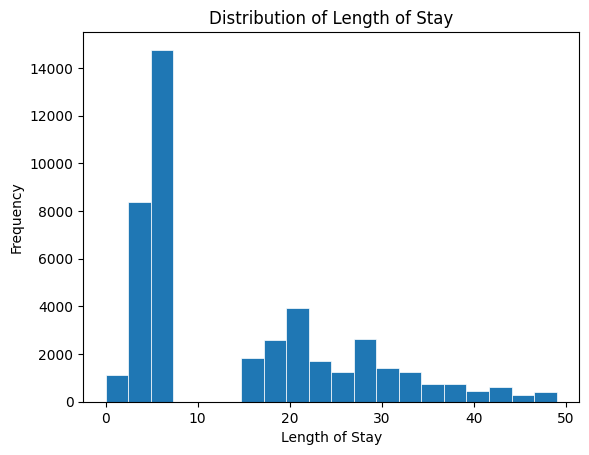

In [11]:
fig, ax = plt.subplots()
ax.hist(df[df['length_of_stay'] < 50].length_of_stay, bins=20, linewidth=0.5, edgecolor="white")
ax.set_title('Distribution of Length of Stay')
ax.set_xlabel('Length of Stay')
ax.set_ylabel('Frequency')
plt.show()

* Obvious Class Imbalance

Text(0.5, 1.0, 'Completed Sales Channel Distribution')

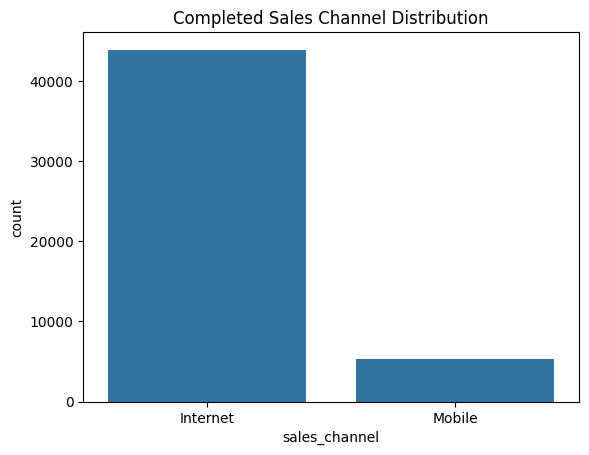

In [12]:
sns.countplot(x = 'sales_channel', data=df)
plt.title('Completed Sales Channel Distribution')

Text(0.5, 1.0, 'Completed Trip Type Distribution')

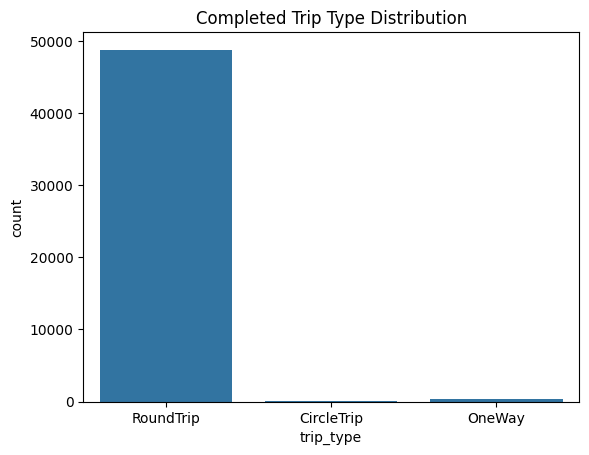

In [13]:
sns.countplot(x = 'trip_type', data=df)
plt.title('Completed Trip Type Distribution')

* Trip types are almost all Roundtrips, which means that this column is a redandant column and doesn't provide any information to the model.

## Data Preprocessing

Data Preparation will include :
* Adding new featuers
* split the data
* Handling outliers
* encoding categorical featuers
* scaling numeric columns


In [14]:
#adding new feature
df.loc[:, 'extra_services'] = (
    (df['wants_extra_baggage'] == 1) |
    (df['wants_preferred_seat'] == 1) |
    (df['wants_in_flight_meals'] == 1)
).astype(int)
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete,extra_services
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0,1
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0,1
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0,1
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0,1


In [43]:
#split data into features and target
from sklearn.model_selection import train_test_split

X = df.drop(columns=['booking_complete', 'trip_type', 'sales_channel'])
y = df['booking_complete']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
X_train.head()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,extra_services
32040,4,69,4,1,Thu,HKTPUS,South Korea,1,0,0,6.33,1
16012,2,126,17,3,Thu,KCHMEL,Australia,1,0,0,8.83,1
41827,2,20,5,23,Mon,PERSIN,Singapore,1,0,0,5.62,1
8656,1,25,28,8,Thu,DELSUB,Indonesia,1,0,0,5.52,1
6110,3,231,64,13,Tue,COKMEL,Australia,1,0,1,8.83,1


In [46]:
X_train_encoded.shape

(39424, 6)

In [52]:
from sklearn.preprocessing import TargetEncoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X_train['flight_day'] = le.fit_transform(X_train['flight_day'])
X_test['flight_day'] = le.transform(X_test['flight_day'])

# TargetEncoder works great for high cardinality
te = TargetEncoder(smooth="auto")
cols = ['booking_origin', 'route']
for col in cols:
  X_train[col] = te.fit_transform(X_train[[col]], y_train)
  X_test[col] = te.transform(X_test[[col]])

In [53]:
X_train

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,extra_services
32040,4,69,4,1,4,0.017243,0.102787,1,0,0,6.33,1
16012,2,126,17,3,4,0.202333,0.052204,1,0,0,8.83,1
41827,2,20,5,23,1,0.000000,0.262234,1,0,0,5.62,1
8656,1,25,28,8,4,0.165277,0.265839,1,0,0,5.52,1
6110,3,231,64,13,5,0.072742,0.050127,1,0,1,8.83,1
...,...,...,...,...,...,...,...,...,...,...,...,...
11435,2,3,52,23,0,0.257516,0.209863,1,0,0,5.07,1
45357,1,19,6,22,2,0.152064,0.121677,0,0,0,7.00,0
38667,3,43,5,10,1,0.061094,0.122366,0,0,0,7.57,0
874,2,294,22,14,1,0.205736,0.342732,1,0,1,8.83,1


In [58]:
# Handle outliers: RobustScaler automatically handels outiliers by using
# the median and interquartile range, making it more robust to outliers than StandardScaler.
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [63]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_train_scaled_df


,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,extra_services
0,3.0,0.193548,-0.565217,-1.000,0.25,-0.635178,-0.013357,0.0,0.0,0.0,-0.386293,0.0
1,1.0,0.806452,0.000000,-0.750,0.25,0.509940,-0.287804,0.0,0.0,0.0,0.392523,0.0
2,1.0,-0.333333,-0.521739,1.750,-0.50,-0.741859,0.851760,0.0,0.0,0.0,-0.607477,0.0
3,0.0,-0.279570,0.478261,-0.125,0.25,0.280683,0.871325,0.0,0.0,0.0,-0.638629,0.0
4,2.0,1.935484,2.043478,0.500,0.50,-0.291817,-0.299072,0.0,0.0,1.0,0.392523,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
39419,1.0,-0.516129,1.521739,1.750,-0.75,0.851348,0.567611,0.0,0.0,0.0,-0.778816,0.0
39420,0.0,-0.344086,-0.478261,1.625,-0.25,0.198935,0.089135,-1.0,0.0,0.0,-0.177570,-1.0
39421,2.0,-0.086022,-0.521739,0.125,-0.50,-0.363881,0.092873,-1.0,0.0,0.0,0.000000,-1.0
39422,1.0,2.612903,0.217391,0.625,-0.50,0.530996,1.288522,0.0,0.0,1.0,0.392523,0.0


## **Modeling**
Dealing with class imbalance in the target column is a bit tricky, because we can't drop it.

Common ways to deal with class imbalance:
* Undersampling: Deleting random instances from the majority class to balance the ratio.
* Class Weighting: Using parameters to automatically adjust the importance of each class.
* Use metrics like Precision, Recall, and F1-Score.

Which metric to optimize? (This is the real question)

**Business wise:**

* What happens if you miss a “Yes booking”?
You lose a potential customer → bad
* What happens if you predict "Yes" but it's actually "No"?
You might target them with marketing → less bad

In [87]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb # Import xgboost

# 1. Logistic Regression
lr = LogisticRegression(class_weight='balanced', random_state=42)

# 2. Random Forest
rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# 3. XGBoost
gb = xgb.XGBClassifier(scale_pos_weight = 85/15, random_state=42)

In [82]:
from sklearn.model_selection import StratifiedKFold # to preserve the class distribution

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [102]:
from sklearn.model_selection import cross_val_score

lr_scores = cross_val_score(lr, X_train_scaled, y_train, cv=cv, scoring='recall')
print(f"Logistic regression Recall: {lr_scores}")

rf_scores = cross_val_score(rf, X_train_scaled, y_train, cv=cv, scoring='recall')
print(f"Random forest Recall: {rf_scores}")

gb_scores = cross_val_score(gb, X_train_scaled, y_train, cv=cv, scoring='recall')
print(f"XGBoost Recall: {gb_scores}")

Logistic regression Recall: [0.72081218 0.70812183 0.7032967  0.69568893 0.70642978]
Random forest Recall: [0.07106599 0.09221658 0.07607777 0.08284024 0.08037225]
XGBoost Recall: [0.61505922 0.63959391 0.62214708 0.63482671 0.62690355]


In [112]:
lr_acc = cross_val_score(lr, X_train_scaled, y_train, cv=cv, scoring='accuracy')
print(f"Logistic regression Accuracy: {lr_acc}")

rf_acc = cross_val_score(rf, X_train_scaled, y_train, cv=cv, scoring='accuracy')
print(f"Random forest Accuracy: {rf_acc}")

gb_acc = cross_val_score(gb, X_train_scaled, y_train, cv=cv, scoring='accuracy')
print(f"XGBoost Accuracy: {gb_acc}")

Logistic regression Recall: [0.71934052 0.71959417 0.717565   0.7203551  0.72222222]
Random forest Recall: [0.84692454 0.85225111 0.85072923 0.85009512 0.85032978]
XGBoost Recall: [0.73772987 0.73874445 0.73760304 0.74090044 0.73680873]


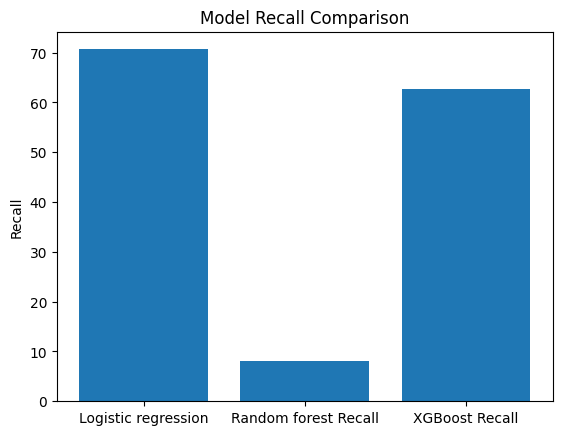

In [118]:
#plot models results
plt.bar(['Logistic regression', 'Random forest Recall', 'XGBoost Recall'], [lr_scores.mean()*100, rf_scores.mean()*100, gb_scores.mean()*100])
plt.ylabel('Recall')
plt.title('Model Recall Comparison')
plt.show()

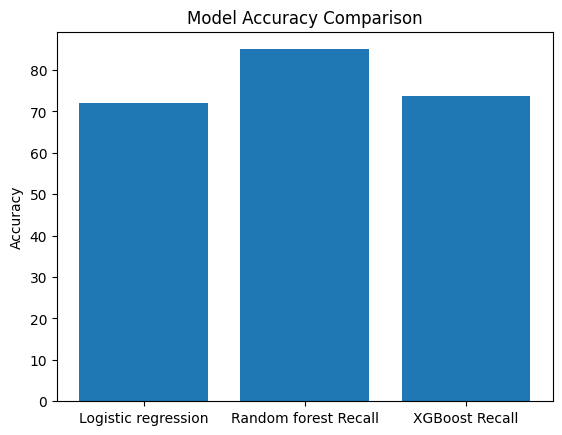

In [116]:
#plot models results
plt.bar(['Logistic regression', 'Random forest Recall', 'XGBoost Recall'], [lr_acc.mean()*100, rf_acc.mean()*100, gb_acc.mean()*100])
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.show()

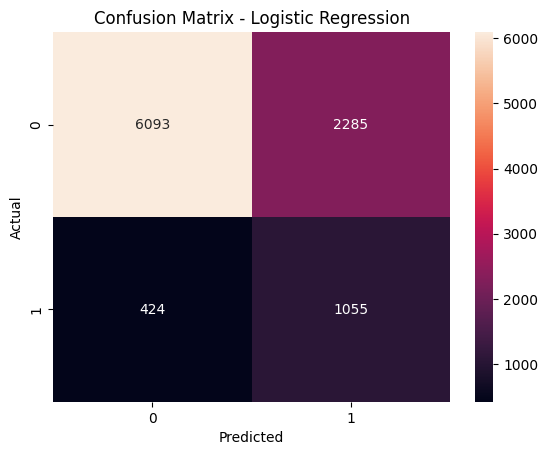

In [108]:
from sklearn.metrics import confusion_matrix

lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)
cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [104]:
from sklearn.metrics import classification_report
print(classification_report(y_test, lr_preds))

              precision    recall  f1-score   support

           0       0.93      0.73      0.82      8378
           1       0.32      0.71      0.44      1479

    accuracy                           0.73      9857
   macro avg       0.63      0.72      0.63      9857
weighted avg       0.84      0.73      0.76      9857



# **Conclusion**

**Key Insights:**

* The model achieves 71% recall for booking customers , meaning:
  - It successfully identifies 7 out of every 10 potential customers

* Precision for bookings is 32% , meaning:

  - Many predicted “bookings” are false positives

* Overall accuracy is 73% , but this is not the focus due to imbalance

**Business Interpretation**

What the model does well:
* Captures the majority of potential customers (high recall)
* Ensures fewer missed opportunities for bookings
* Supports proactive targeting strategies

Trade-off:

* Lower precision means, The business may target some customers who will not actually book

* However, in most real-world scenarios, Missing a potential customer is more costly than contacting a non-interested one

**Business Value**

This model can be used to:

* Target high-probability customers with promotions or reminders
* Increase conversion rates through better customer selection
* Optimize marketing budget by focusing on likely converters

Even with moderate precision, the high recall ensures maximum opportunity capture , which is often the priority in customer acquisition problems.